# SimCIM Visualiazer

This notebook aims at visualizing SimCIM execution

In [1]:
%matplotlib notebook
import numpy as np
import pandas as pd

from numpy import arctan
from numpy import pi

from scipy.optimize import curve_fit
from matplotlib import pyplot as plt

In [21]:
path_to_output = './cmake-build-debug/output.txt'

In [34]:
output = pd.read_table(path_to_output)

In [23]:
python_pump = np.loadtxt('./python_pump.txt')

In [24]:
k_local_pump = np.loadtxt('./k_local_pump_values.txt')

<IPython.core.display.Javascript object>


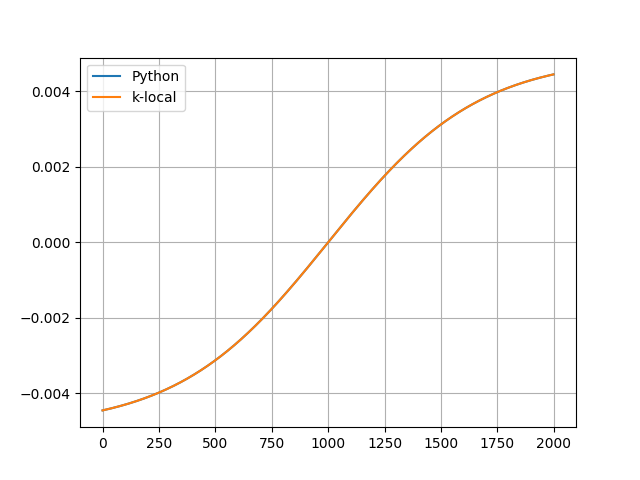

In [25]:
fig, ax = plt.subplots()
ax.grid()
#ax.plot(output['t'], output['pump'], label='C++')
ax.plot(python_pump, label='Python')
ax.plot(k_local_pump, label='k-local')

ax.legend(loc='best')

<IPython.core.display.Javascript object>


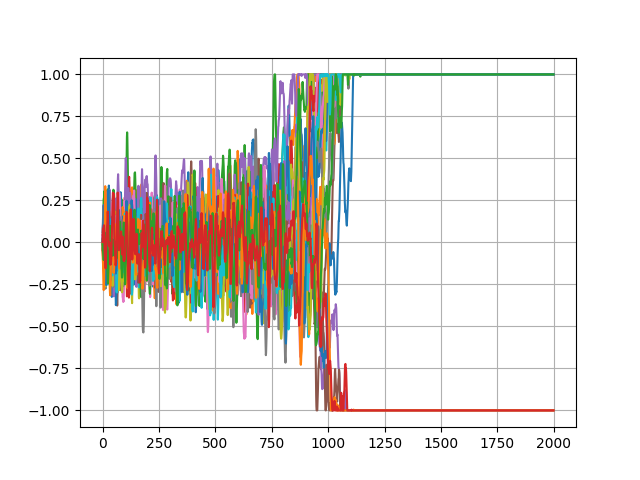

In [38]:
output = pd.read_table(path_to_output)
fig, ax = plt.subplots()
ax.grid()
for col in output.columns:
    if col != 't' and col != 'pump':
        ax.plot(output['t'], output[col])

<IPython.core.display.Javascript object>


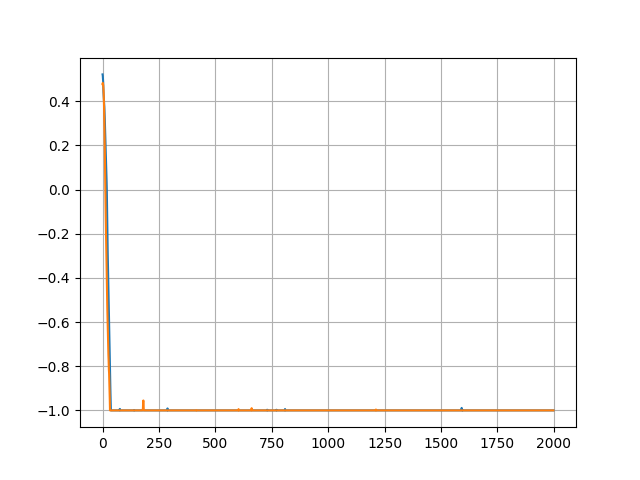

In [22]:
python_evol = np.loadtxt('./python_evol.txt')
fig, ax = plt.subplots()
ax.grid()
for row_idx in range(python_evol.shape[0]):
    ax.plot(python_evol[row_idx, :])

<IPython.core.display.Javascript object>


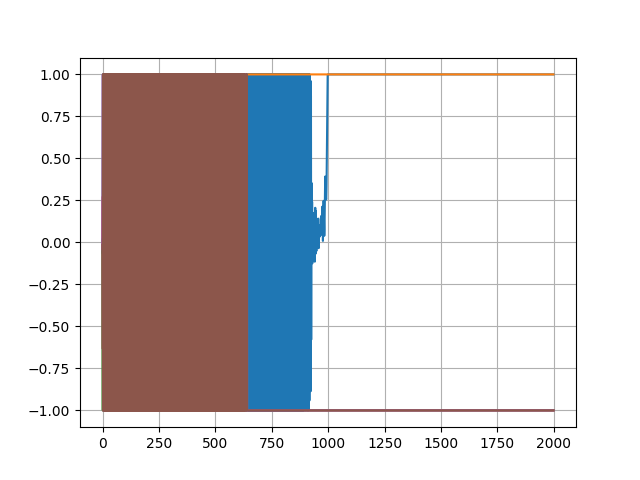

In [33]:
k_local_evol = np.loadtxt('./k_local_evol.txt')
fig, ax = plt.subplots()
ax.grid()
for row_idx in range(k_local_evol.shape[0]):
    ax.plot(k_local_evol[row_idx, :])

In [34]:
print(k_local_evol[:, -1])

[ 1.  1. -1. -1. -1. -1.]


In [9]:
x_axis = np.arange(1, 12, 1)
data_to_build = {
    'qubit_num' : {
        'PUBO': np.array([2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22]),
        'QUBO': np.array([2, 10, 24, 44, 70, 102, 140, 184, 234, 290, 352]),
    },
    'terms_num': {
        'PUBO': np.array([4, 16, 37, 67, 106, 154, 211, 277, 352, 436, 529]),
        'QUBO': np.array([4, 35, 94, 181, 296, 439, 610, 809, 1036, 1291, 1574]),
    }
}

<IPython.core.display.Javascript object>


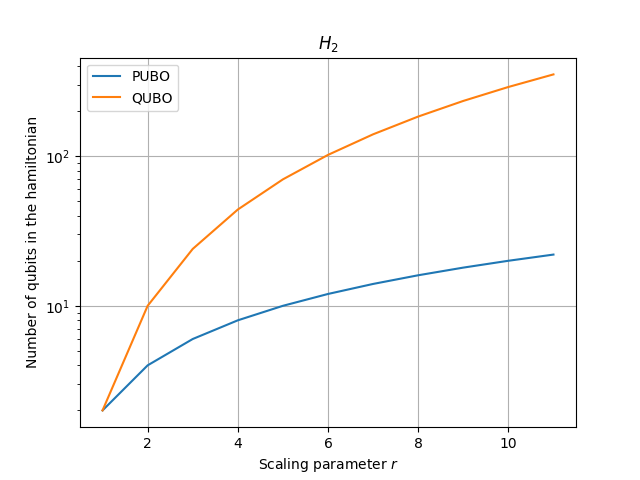

<IPython.core.display.Javascript object>


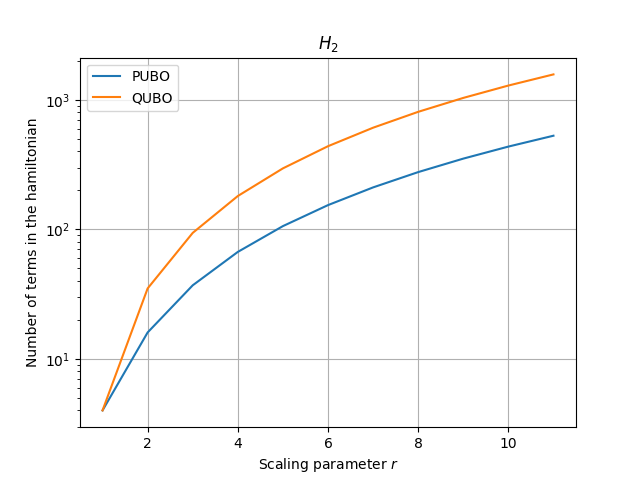

In [11]:
plot_to_ylabel = {
    'qubit_num': 'Number of qubits in the hamiltonian',
    'terms_num': 'Number of terms in the hamiltonian'
}
for plot in data_to_build:
    fig, ax = plt.subplots()
    ax.grid()
    for method in data_to_build[plot]:
        ax.plot(x_axis, data_to_build[plot][method], label=method)
        
    ax.legend(loc='best')
        
    ax.set_xlabel('Scaling parameter $r$')
    ax.set_ylabel(plot_to_ylabel[plot])
    ax.set_yscale('log')
    ax.set_title('$H_2$')